<a href="https://colab.research.google.com/github/miapham839/Inner-Forcast/blob/main/Program_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 3: Panoramic Image Stitching

This is Program 3 for [COMSC 341-CV Computer Vision](https://mtholyoke.instructure.com/courses/4119).

**This project:**

In this project you will implement a panoramic image stitcher. This will build on the interest points and descriptors developed in Project 2. You'll begin with geometric filtering via RANSAC, then estimate pairwise rotations and chain these together to align the panorama. When you have a basic stitcher working, improve it with better alignment, blending, or other new features and document your findings.

**What to turn in:**

On your completed `Program3.ipynb`, click File->Save, and choose the private repository you created. Remember to go back to the repository and make sure the updated notebook file is successfully uploaded.

Note: Double check that your submission clearly described any enhancements or experiments you tried and answered all the <font color='Tomato'>questions</font> in your ipynb notebook. Your writeup should be marked in <font color='MediumSeaGreen'>green</font>.

`ver. 090926`


*   Student Name:  <font color='MediumSeaGreen'>Mia Pham</font>
*   Student Email:  <font color='MediumSeaGreen'>pham222h@mtholyoke.edu</font>


In [ ]:
import numpy as np
import scipy.linalg
import os.path
from time import time
import types
import matplotlib.pyplot as plt

%matplotlib inline
# edit this line to change the figure size
plt.rcParams['figure.figsize'] = (12.0, 8.0)

In [ ]:
# find the file pano_images.zip locally from your computer
from google.colab import files
f = files.upload()

Saving P3Data.zip to P3Data.zip


In [ ]:
# run this command to unzip the images in colab
!unzip -n -d data P3Data.zip

Archive:  P3Data.zip
  inflating: data/100-0023_img.jpg   
  inflating: data/100-0024_img.jpg   
  inflating: data/100-0025_img.jpg   
  inflating: data/100-0038_img.jpg   
  inflating: data/100-0039_img.jpg   
  inflating: data/100-0040_img.jpg   
  inflating: data/101-0104_img.jpg   
  inflating: data/test/cr_H.npy      
  inflating: data/test/cr_R.npy      
  inflating: data/test/fso_nm.npy    
  inflating: data/test/fso_order.npy  


## Reusing Old Classes

### ImUtil class
The class includes essential image processing functions for convolution and filtering. Make a copy of your completed `ImUtil` class from Program1 to the code cell below. You do NOT need to make further changes to this part of the code in this assignment.

In [ ]:
# Copyright 2017 Google Inc.

# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at

# https://www.apache.org/licenses/LICENSE-2.0

# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

import math
import numpy as np
import PIL.Image as pil
import scipy.signal as sps
import scipy.stats as stats
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates

class ImUtil():

  def convolve_1d(self, x, k):
    """
    Convolve vector x with kernel k

    Inputs: x=input vector (Nx)
            k=input kernel (Nk)

    Outputs: y=output vector (Nx)
    """
    y=np.zeros_like(x)

    """
    *******************************************
    *** TODO: write code to perform convolution
    *******************************************

    The output should be the same size as the input
    You can assume zero padding, and an odd-sized kernel
    """
    for i in range(len(k)//2):
      x = np.concatenate([[0],x,[0]])

    for i in range(len(y)):
      for j in range(len(k)):
        y[i] += k[j]*x[i+j]


    """
    *******************************************
    """

    return y

  def convolve_rows(self, im, k):
    """
    Convolve image im with kernel k

    Inputs: im=input image (H, W, B)
            k=1D convolution kernel (N)

    Outputs: im_out=output image (H, W, B)
    """
    im_out = np.zeros_like(im)

    """
    *****************************************
    *** TODO: write code to convolve an image
    *****************************************
    """
    for i in range(im.shape[0]):
      for j in range(im.shape[2]):
        im_out[i,:,j] = self.convolve_1d(im[i,:,j], k)

    """
    *****************************************
    """

    return im_out

  def gauss_kernel(self, sigma):
    """
    1D Gauss kernel of standard deviation sigma
    """
    l = int(np.ceil(2 * sigma))
    x = np.linspace(-l, l, 2*l+1)

    # FORNOW
    gx = np.zeros_like(x)

    """
    *******************************************
    *** TODO: compute gaussian kernel at each x
    *******************************************
    """
    gx = np.exp(-x**2/(2*sigma**2))
    gx = gx/np.sum(gx)
    """
    *******************************************
    """

    # gx = np.expand_dims(gx,0)
    return gx

  def convolve_gaussian(self, im, sigma):
    """
    2D gaussian convolution
    """
    imc=np.zeros_like(im)

    """
    ***************************************
    *** TODO separable gaussian convolution
    ***************************************
    """
    gx = self.gauss_kernel(sigma)
    imc1 = self.convolve_rows(im, gx)
    imc2 = self.convolve_rows(imc1.transpose(1, 0, 2), gx)
    imc = imc2.transpose(1, 0, 2)
    """
    ***************************************
    """
    return imc

  def compute_gradients(self, img):

    Ix=np.zeros_like(img)
    Iy=np.zeros_like(img)

    """
    ***********************************************
    *** TODO: write code to compute image gradients
    ***********************************************
    """
    k=np.array([[-1,0,1]])
    kt=k.T

    Ix=self.convolve(img, k)
    Iy=self.convolve(img, kt)

    """
    ***********************************************
    """
    return Ix, Iy

  def compute_sobel(self, img):

    Sx=np.zeros_like(img)
    Sy=np.zeros_like(img)

    """
    ***********************************************
    *** TODO: write code to conduct sobel edge detection
    ***********************************************
    """
    kvert = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])
    khori = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]])

    Sx=self.convolve(img, kvert)
    Sy=self.convolve(img, khori)

    """
    ***********************************************
    """
    return Sx, Sy

  def image_open(self, filename):
    """
    Returns a numpy float image with values in the range (0,1)
    """
    pil_im = pil.open(filename)
    im_np = np.array(pil_im).astype(np.float32)
    im_np /= 255.0
    return im_np

  def image_save(self, im_np, filename):
    """
    Saves a numpy float image to file
    """
    if (len(im_np.shape)==2):
      im_np = np.expand_dims(im_np, 2)
    if (im_np.shape[2]==1):
      im_np= np.repeat(im_np, 3, axis=2)
    im_np = np.maximum(0.0, np.minimum(im_np, 1.0))
    pil_im = pil.fromarray((im_np*255).astype(np.uint8))
    pil_im.save(filename)

  def image_figure(self, im, dpi=100):
    """
    Creates a matplotlib figure around an image,
    useful for writing to file with savefig()
    """
    H,W,_=im.shape
    fig=plt.figure()
    fig.set_size_inches(W/dpi, H/dpi)
    ax=fig.add_axes([0,0,1,1])
    ax.imshow(im)
    return fig, ax

  def plot_many_images(self, *imgs):
    """
    Plot two images and return axis handles
    """
    count = len(imgs)
    axs = []
    for i in range(count):
      axs.append(plt.subplot(1,count,i+1))
      plt.imshow(imgs[i])
      plt.axis('off')
    return axs

  def normalise_01(self, im):
    """
    Normalise image to the range (0,1)
    """
    mx = im.max()
    mn = im.min()
    den = mx-mn
    small_val = 1e-9
    if (den < small_val):
      print('image normalise_01 -- divisor is very small')
      den = small_val
    return (im-mn)/den

  def channel_expand(self, img):
    """
    Convert greyscale to rgb image
    """
    if (len(img.shape)==2):
      img = np.expand_dims(img, 2)

    img3 = np.repeat(img, 3, 2)
    return img3

  def disc_mask(self, l):
    """
    Create a binary cirular mask of radius l
    """
    sz = 2 * l + 1
    m = np.zeros((sz,sz))
    x = np.linspace(-l,l,2*l+1)/l
    x = np.expand_dims(x, 1)
    m = x**2
    m = m + m.T
    m = m<1
    m = np.expand_dims(m, 2)
    return m

  def convolve(self, im, kernel):
    """
    Wrapper for scipy convolution function
    This implements a general 2D convolution of image im with kernel
    Note that strictly speaking this is correlation not convolution

    Inputs: im=input image (H, W, B) or (H, W)
            kernel=kernel (kH, kW)

    Outputs: imc=output image (H, W, B)
    """
    if (len(im.shape)==2):
      im = np.expand_dims(im, 2)
    H, W, B = im.shape
    imc = np.zeros((H, W, B))
    for band in range(B):
      imc[:, :, band] = sps.correlate2d(im[:, :, band], kernel, mode='same')
    return imc

  def coordinate_image(self, num_rows,num_cols,r0,r1,c0,c1):
    """
    Creates an image size num_rows, num_cols
    with coordinates linearly spaced in from r0->r1 and c0->c1
    """
    rval=np.linspace(r0,r1,num_rows)
    cval=np.linspace(c0,c1,num_cols)
    c,r=np.meshgrid(cval,rval)
    M = np.stack([r,c,np.ones(r.shape)],-1)
    return M

  def transform_coordinates(self, coord_image, M):
    """
    Transform an image containing row,col,1 coordinates by matrix M
    """
    M=np.expand_dims(M,2)
    uh=np.dot(coord_image,M.T)
    uh=uh[:, :, 0, :]
    uh=uh/np.expand_dims(uh[:, :, 2],2)
    return uh

  def warp_image(self, im, coords):
    """
    Warp image im using row,col,1 image coords
    """
    im_rows,im_cols,im_bands=im.shape
    warp_rows,warp_cols,_=coords.shape
    map_coords=np.zeros((3,warp_rows,warp_cols,im_bands))
    print("map_coords shape: ",map_coords.shape)

    for b in range(im_bands):
      map_coords[0,:,:,b]=coords[:,:,0]
      map_coords[1,:,:,b]=coords[:,:,1]
      map_coords[2,:,:,b]=b
    warp_im = map_coordinates(im, map_coords, order=1)
    return warp_im

  def rotate_around_center(self, im, ang):
    """
    ***********************************************
    *** TODO: Rotate image in the clockwise direction
    ***       by ang degrees around the image center.
    ***********************************************
    """
    h, w, b = im.shape
    dim = np.array([h,w])
    cx = h//2
    cy = w//2

    ci = self.coordinate_image(h,w,0,h-1,0,w-1)
    ci[:,:,[0,1]] = ci[:,:,[1,0]]

    theta = np.radians(ang)
    trans = np.array([[1,0,-cy], [0,1,-cx], [0,0,1]])
    transrot = np.array([[np.cos(theta),-np.sin(theta),cy],[np.sin(theta),np.cos(theta),cx],[0,0,1]])

    T = transrot @ trans

    ci = self.transform_coordinates(ci,T).astype(int)
    ci[:,:,[1,0]] = ci[:,:,[0,1]]
    im_out = self.warp_image(im, ci)

    return im_out, T

# allow accessing these functions by im_util.*
im_util = ImUtil()

### Application: Image Warping Exercise

In the last part of Program1, we explored functions in the `ImUtil` class to perform image transformations. Here we are going to revisit them. The code below warps an image using a pre-determined 3x3 transformation matrix `P1` and custom designed matix `P2`. Experiment with the matrix `P2` to test some of the different 2D transformations described in class, e.g., similarity, affine and projective transforms.

map_coords shape:  (3, 758, 568, 3)
map_coords shape:  (3, 758, 568, 3)
map_coords shape:  (3, 758, 568, 3)
map_coords shape:  (3, 758, 568, 1)
map_coords shape:  (3, 758, 568, 1)


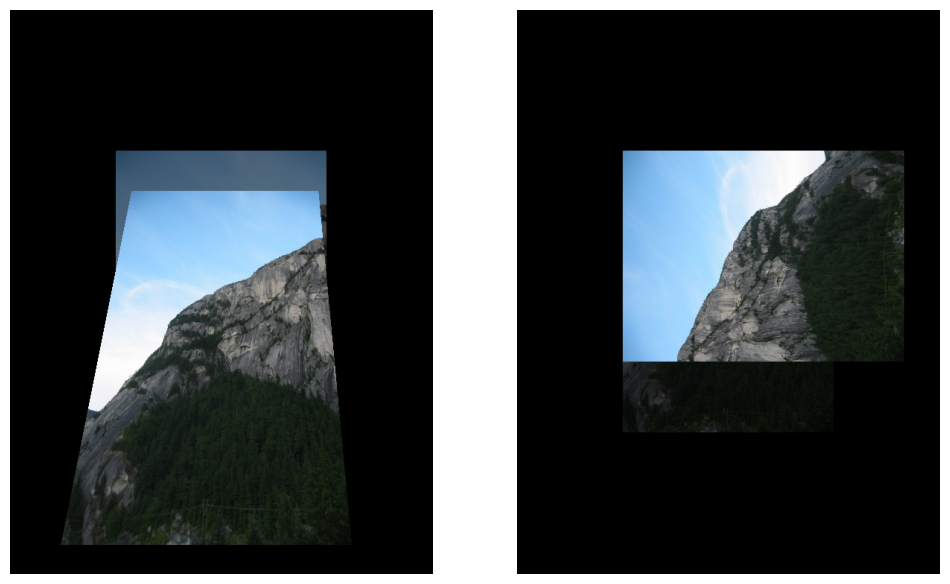

In [ ]:
# read image
image_dir='data/'
im_filename1=image_dir+'100-0038_img.jpg'
im=im_util.image_open(im_filename1)
im_rows,im_cols,_=im.shape

# set transformation matrix
P1=[[ 1,    0.2,  -64],
    [ 0,    1.1, -120],
    [ 0, 5.2e-4, 0.83]]

P2=[[ 1, 0, 0],  #FORNOW
    [ 0, 1, 0],
    [ 0, 0, 1]]
"""
***********************************************
*** TODO: write code to update P2
***********************************************
"""
P2=[[ 0, 1, 0],
    [ 1, 0, 0],
    [ 0, 0, 1]]

"""
***********************************************
"""

# warp coordinates
r0,r1=-im_rows/2, im_rows*3/2
c0,c1=-im_cols/2, im_cols*3/2
warp_rows, warp_cols=im_rows, im_cols

coords_yx=im_util.coordinate_image(warp_rows,warp_cols,r0,r1,c0,c1)
coords_xy = coords_yx[:,:,[1,0,2]]
coords_t1_xy=im_util.transform_coordinates(coords_xy, P1)
coords_t2_xy=im_util.transform_coordinates(coords_xy, P2)

coords_t1_yx = coords_t1_xy[:,:,[1,0,2]]
coords_t2_yx = coords_t2_xy[:,:,[1,0,2]]

# visualise result
warp_im=im_util.warp_image(im,coords_yx)
warp_im1=im_util.warp_image(im,coords_t1_yx)
warp_im2=im_util.warp_image(im,coords_t2_yx)

alpha1=im_util.warp_image(np.ones((im_rows,im_cols,1)),coords_t1_yx)
alpha2=im_util.warp_image(np.ones((im_rows,im_cols,1)),coords_t2_yx)
result_im1=warp_im1*alpha1 + 0.5*warp_im*(1-alpha1)
result_im2=warp_im2*alpha2 + 0.5*warp_im*(1-alpha2)

axs = im_util.plot_many_images(result_im1, result_im2)

### InterestPointExtractor class & DescriptorExtractor class
Make a copy of your completed `InterestPointExtractor` and `DescriptorExtractor` classes from Program2 to the code cell below. You do NOT need to make further changes to this part of the code for this assignment.

In [ ]:
# Copyright 2017 Google Inc.

# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at

# https://www.apache.org/licenses/LICENSE-2.0

# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

import math

import numpy as np
import scipy.ndimage as spy
from scipy.ndimage import filters, map_coordinates, rotate
from scipy import stats
from matplotlib.patches import Circle
import matplotlib.pyplot as plt

class InterestPointExtractor:
    """
    Class to extract interest points from an image
    """
    def __init__(self):
      self.params={}
      self.params['border_pixels']=10
      self.params['strength_threshold_percentile']=95
      self.params['supression_radius_frac']=0.01
      self.DOG = 1
      self.HARRIS_SIM = 2
      self.HARRIS_HAR = 3

    def find_interest_points(self, img):
      """
      Find interest points in greyscale image img

      Inputs: img=greyscale input image (H, W, 1)

      Outputs: ip=interest points of shape (2, N)
      """
      ip_fun = self.corner_function(img)
      row, col = self.find_local_maxima(ip_fun)

      ip = np.stack((row,col))
      return ip

    def dog_corner(self, img):
      """
      Compute DOG corner strength function in image im

      Inputs: img=grayscale input image (H, W, 1)

      Outputs: ip_fun=interest point strength function (H, W, 1)
      """
      H, W, _ = img.shape

      # FORNOW: random interest point function
      ip_fun = np.random.randn(H, W, 1)
      """
      **********************************************************
      *** TODO: write code to compute a DOG corner function
      **********************************************************
      """
      gsmall = im_util.convolve_gaussian(img, 1)
      glarge = im_util.convolve_gaussian(img, 10)
      ip_fun = (glarge - gsmall)


      """
      **********************************************************
      """
      return ip_fun

    def harris_corner(self, img, corner_fn):
      """
      Compute two HARRIS corner strength function in image im

      Inputs: img=grayscale input image (H, W, 1)
              corner_fn=2: for SIMPLE HARRIS detection
                        3: for HARMONIC HARRIS detection

      Outputs: ip_fun=interest point strength function (H, W, 1)
      """
      H, W, _ = img.shape

      # FORNOW: random interest point function
      ip_fun = np.random.randn(H, W, 1)
      """
      **********************************************************
      *** TODO: write code to compute HARRIS corner functions
      **********************************************************
      """
      # First, we need to get the gradients
      Ix, Iy = im_util.compute_gradients(img)
      Ix = Ix[:, :, 0]
      Iy = Iy[:, :, 0]

      # Finding the gradient products for the matrix
      Ix2 = Ix**2
      Iy2 = Iy**2
      IxIy = Ix * Iy

      # Use the convolve_gaussian function to find the sums of the products
      A = im_util.convolve_gaussian(Ix2[:, :, np.newaxis], 1)[:, :, 0]
      B = im_util.convolve_gaussian(Iy2[:, :, np.newaxis], 1)[:, :, 0]
      C = im_util.convolve_gaussian(IxIy[:, :, np.newaxis], 1)[:, :, 0]

      # Determinant
      det = A * B - C**2

      # Trace
      trace = A + B

      # Simple harris
      if corner_fn == self.HARRIS_SIM:
        alpha = 0.05
        ip_fun = det - alpha * trace**2

      # Harmonic harris
      elif corner_fn == self.HARRIS_HAR:
        ip_fun = det / np.maximum(trace, 1e-9) # So we are not diving by 0

      # Adding all the dimensions back to the image
      ip_fun = ip_fun[:, :, np.newaxis]

      """
      **********************************************************
      """
      return ip_fun

    def corner_function(self, img, corner_fn=1):
      """
      Compute corner strength function in image im

      Inputs: img=grayscale input image (H, W, 1)
              corner_fn=1: for DOG corner detection
                        2: for SIMPLE HARRIS detection
                        3: for HARMONIC HARRIS detection

      Outputs: ip_fun=interest point strength function (H, W, 1)
      """
      H, W, _ = img.shape

      if corner_fn == self.HARRIS_SIM or corner_fn == self.HARRIS_HAR:
        ip_fun = self.harris_corner(img, corner_fn)

      elif corner_fn == self.DOG:
        ip_fun = self.dog_corner(img)

      else:
        print("Your choice of corner_fn is invalid. (Please select: 1,2, or 3)")
        # random interest point function
        ip_fun = np.random.randn(H, W, 1)

      return ip_fun


    def find_local_maxima(self, ip_fun):
      """
      Find local maxima in interest point strength function

      Inputs: ip_fun=corner strength function (H, W, 1)

      Outputs: row,col=coordinates of interest points
      """

      H, W, _ = ip_fun.shape

      # radius for non-maximal suppression
      suppression_radius_pixels = int(self.params['supression_radius_frac']*max(H, W))

      # minimum of strength function for corners
      strength_threshold=np.percentile(ip_fun, self.params['strength_threshold_percentile'])

      # don't return interest points within border_pixels of edge
      border_pixels = self.params['border_pixels']

      # row and column coordinates of interest points
      row = []
      col = []

      # FORNOW: random row and column coordinates
      # row = np.random.randint(0,H,100)
      # col = np.random.randint(0,W,100)

      """
      ***************************************************
      *** TODO: write code to find local maxima in ip_fun
      ***************************************************

      Hint: try scipy maximum_filter with im_util.disc_mask
      """
      # Get a 2D array
      strength = ip_fun[:, :, 0]

      # Circular neighborhood is created
      radius = max(1, suppression_radius_pixels)
      dMask = im_util.disc_mask(radius)[:, :, 0]

      # Finding max value in each circular neighborhood
      IM = spy.maximum_filter(strength, footprint = dMask)

      # Keep only the pixels that are local maxima and above the
      # calculated strength threshold from above
      kept_pixels = (strength == IM) & (strength >= strength_threshold)

      # Removing the points that are near the borders of image
      # Top boarder
      kept_pixels[:border_pixels, :] = False
      # Bottom border
      kept_pixels[-border_pixels:, :] = False
      # Left side
      kept_pixels[:, :border_pixels] = False
      # Right side
      kept_pixels[:, -border_pixels:] = False

      row, col = np.where(kept_pixels)
      """
      ***************************************************
      """

      return row, col

    def draw_interest_points_ax(self, ip, ax):
      """
      Draw interest points ip on axis ax
      """
      for row,col in zip(ip[0,:],ip[1,:]):
        circ1 = Circle((col,row), 5)
        circ1.set_color('black')
        circ2 = Circle((col,row), 3)
        circ2.set_color('white')
        ax.add_patch(circ1)
        ax.add_patch(circ2)

    def draw_interest_points_file(self, im, ip, filename):
      """
      Draw interest points ip on image im and save to filename
      """
      fig,ax = im_util.image_figure(im)
      self.draw_interest_points_ax(ip, ax)
      fig.savefig(filename)
      plt.close(fig)

class DescriptorExtractor:
    """
    Extract descriptors around interest points
    """
    def __init__(self):
      self.params={}
      self.params['patch_size']=8
      # FORNOW:   self.params['ratio_threshold']=1.0
      self.params['ratio_threshold']=0.6

    def get_descriptors(self, img, ip):
      """
      Extact descriptors from grayscale image img at interest points ip

      Inputs: img=grayscale input image (H, W, 1)
              ip=interest point coordinates (2, N)

      Returns: descriptors=vectorized descriptors (N, num_dims)
      """
      patch_size=self.params['patch_size']
      patch_size_div2=int(patch_size/2)
      num_dims=patch_size**2

      H,W,_=img.shape
      num_ip=ip.shape[1]
      descriptors=np.zeros((num_ip,num_dims))


      for i in range(num_ip):
        row=ip[0,i]
        col=ip[1,i]

        # FORNOW: random image patch
        patch=np.random.randn(patch_size,patch_size)

        """
        ******************************************************
        *** TODO: write code to extract descriptor at row, col
        ******************************************************
        """
        patch=img[row - patch_size_div2:row + patch_size_div2, col - patch_size_div2:col + patch_size_div2]

        """
        ******************************************************
        """

        descriptors[i, :]=np.reshape(patch,num_dims)

      # normalise descriptors to 0 mean, unit length
      mn=np.mean(descriptors,1,keepdims=True)
      sd=np.std(descriptors,1,keepdims=True)
      small_val = 1e-6
      descriptors = (descriptors-mn)/(sd+small_val)

      return descriptors

    def compute_distances(self, desc1, desc2):
      """
      Compute distances between descriptors

      Inputs: desc1=descriptor array (N1, num_dims)
              desc2=descriptor array (N2, num_dims)

      Returns: dists=array of distances (N1,N2)
      """
      N1,num_dims=desc1.shape
      N2,num_dims=desc2.shape

      #FORNOW
      dists= np.zeros((N1, N2))
      """
      ******************************************************
      *** TODO: write code calculate distance between desc1 and desc2
      ******************************************************
      """
      for i in range(N1):
        diff = desc2 - desc1[i]
        dists[i] = np.sum(diff**2, axis=1)
      """
      ******************************************************
      """
      return dists

    def match_descriptors(self, desc1, desc2):
      """
      Find nearest neighbour matches between descriptors

      Inputs: desc1=descriptor array (N1, num_dims)
              desc2=descriptor array (N2, num_dims)

      Returns: match_idx=nearest neighbour index for each desc1 (N1)
      """
      dists=self.compute_distances(desc1, desc2)

      match_idx=np.argmin(dists,1)

      return match_idx

    def match_ratio_test(self, desc1, desc2):
      """
      Find nearest neighbour matches between descriptors
      and perform ratio test

      Inputs: desc1=descriptor array (N1, num_dims)
              desc2=descriptor array (N2, num_dims)

      Returns: match_idx=nearest neighbour inded for each desc1 (N1)
              ratio_pass=whether each match passes ratio test (N1)
      """
      N1,num_dims=desc1.shape

      dists=self.compute_distances(desc1, desc2) # N1 x N2

      sort_idx=np.argsort(dists,1)

      #match_idx=np.argmin(dists,1)
      match_idx=sort_idx[:,0]

      d1NN=dists[np.arange(0,N1),sort_idx[:,0]]
      d2NN=dists[np.arange(0,N1),sort_idx[:,1]]

      ratio_threshold=self.params['ratio_threshold']
      ratio_pass=(d1NN<ratio_threshold*d2NN)

      return match_idx,ratio_pass

    def draw_matches_ax(self, ip1, ipm, ax1, ax2):
      """
      Draw matches ip1, ipm on axes ax1, ax2
      """
      for r1,c1,r2,c2 in zip(ip1[0,:], ip1[1,:], ipm[0,:], ipm[1,:]):
        rand_colour=np.random.rand(3,)

        circ1 = Circle((c1,r1), 5)
        circ1.set_color('black')
        circ2 = Circle((c1,r1), 3)
        circ2.set_color(rand_colour)
        ax1.add_patch(circ1)
        ax1.add_patch(circ2)

        circ3 = Circle((c2,r2), 5)
        circ3.set_color('black')
        circ4 = Circle((c2,r2), 3)
        circ4.set_color(rand_colour)
        ax2.add_patch(circ3)
        ax2.add_patch(circ4)

    def draw_matches_file(self, im1, im2, ip1, ipm, filename):
      """
      Draw matches ip1, ipm on images im1, im2 and save to filename
      """
      H1,W1,B1=im1.shape
      H2,W2,B2=im2.shape

      im3 = np.zeros((max(H1,H2),W1+W2,3))
      im3[0:H1,0:W1,:]=im1
      im3[0:H2,W1:(W1+W2),:]=im2

      fig,ax = im_util.image_figure(im3)
      col_offset=W1

      for r1,c1,r2,c2 in zip(ip1[0,:], ip1[1,:], ipm[0,:], ipm[1,:]):
        rand_colour=np.random.rand(3,)

        circ1 = Circle((c1,r1), 5)
        circ1.set_color('black')
        circ2 = Circle((c1,r1), 3)
        circ2.set_color(rand_colour)
        ax.add_patch(circ1)
        ax.add_patch(circ2)

        circ3 = Circle((c2+col_offset,r2), 5)
        circ3.set_color('black')
        circ4 = Circle((c2+col_offset,r2), 3)
        circ4.set_color(rand_colour)
        ax.add_patch(circ3)
        ax.add_patch(circ4)

      fig.savefig(filename)
      plt.close(fig)

    def plot_descriptors(self, desc,plt):
      """
      Plot a random set of descriptor patches
      """
      num_ip,num_dims = desc.shape
      patch_size = int(np.sqrt(num_dims))

      N1,N2=2,8
      figsize0=plt.rcParams['figure.figsize']
      plt.rcParams['figure.figsize'] = (16.0, 4.0)
      for i in range(N1):
        for j in range(N2):
          ax=plt.subplot(N1,N2,i*N2+j+1)
          rnd=np.random.randint(0,num_ip)
          desc_im=np.reshape(desc[rnd,:],(patch_size,patch_size))
          plt.imshow(im_util.channel_expand(im_util.normalise_01(desc_im)))
          plt.axis('off')

      plt.rcParams['figure.figsize']=figsize0

    def plot_matching_descriptors(self,desc1,desc2,desc1_id,desc2_id,plt):
      """
      Plot a random set of matching descriptor patches
      """
      num_inliers=desc1_id.size
      num_ip,num_dims = desc1.shape
      patch_size=int(np.sqrt(num_dims))

      figsize0=plt.rcParams['figure.figsize']

      N1,N2=1,8
      plt.rcParams['figure.figsize'] = (16.0, N1*4.0)

      for i in range(N1):
        for j in range(N2):
          rnd=np.random.randint(0,num_inliers)

          desc1_rnd=desc1_id[rnd]
          desc2_rnd=desc2_id[rnd]

          desc1_im=np.reshape(desc1[desc1_rnd,:],(patch_size,patch_size))
          desc2_im=np.reshape(desc2[desc2_rnd,:],(patch_size,patch_size))

          ax=plt.subplot(2*N1,N2,2*i*N2+j+1)
          plt.imshow(im_util.channel_expand(im_util.normalise_01(desc1_im)))
          plt.axis('off')
          ax=plt.subplot(2*N1,N2,2*i*N2+N2+j+1)
          plt.imshow(im_util.channel_expand(im_util.normalise_01(desc2_im)))
          plt.axis('off')

      plt.rcParams['figure.figsize'] = figsize0

ip_ex = InterestPointExtractor()
desc_ex = DescriptorExtractor()

### Application: Interest Points Detection

We will use the interest points and descriptors implemented in Program2.

Run the code block below to check your interest points and descriptors are working. For subsequent steps to run well, you should aim for about 100-1000 matches and about 30-50 matches that pass the ratio test.


[ find interest points ]
 found 312 in image 1
 found 421 in image 2
  100.64 secs 

[ extract descriptors ]
  0.01 secs

[ match descriptors ]
 found 312 matches
 found 20 matches (that pass the ratio test)
  0.08 secs

[ drawing interest points and matches]
  5.25 secs


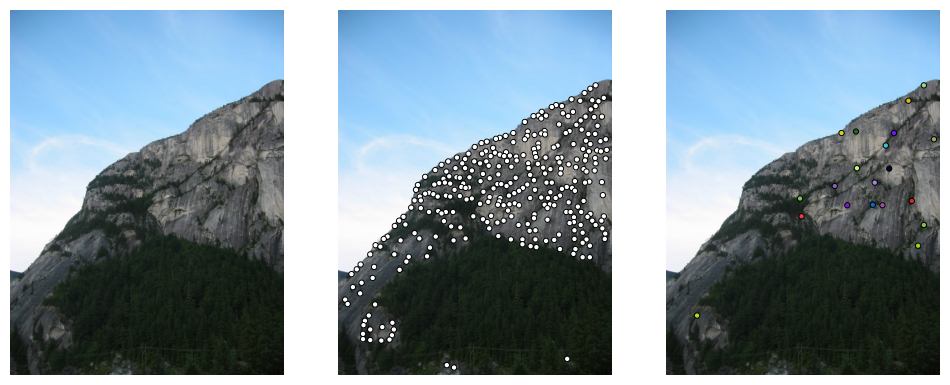

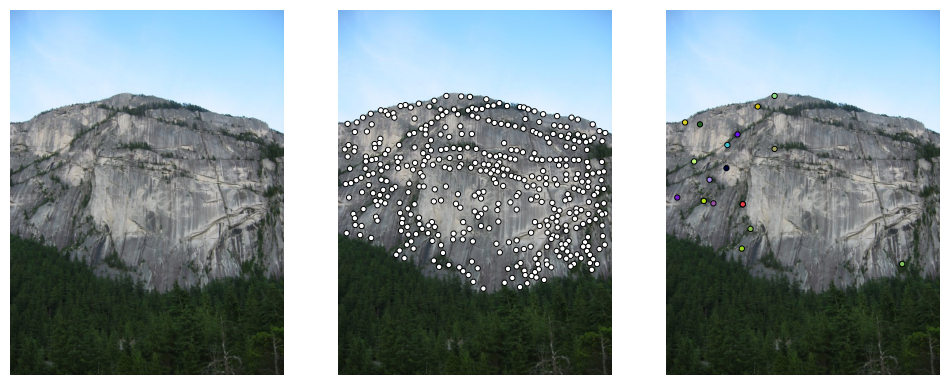

In [ ]:
"""
Read a pair of input images and convert to grey
"""
image_dir='data/'
#im_filename1=image_dir+'100-0023_img.jpg'
#im_filename2=image_dir+'100-0024_img.jpg'
im_filename1=image_dir+'100-0038_img.jpg'
im_filename2=image_dir+'100-0039_img.jpg'

im1 = im_util.image_open(im_filename1)
im2 = im_util.image_open(im_filename2)

img1 = np.mean(im1, 2, keepdims=True)
img2 = np.mean(im2, 2, keepdims=True)

"""
Find interest points in the image pair
"""
print('\n[ find interest points ]')
t0=time()
ip1 = ip_ex.find_interest_points(img1)
print(' found '+str(ip1.shape[1])+' in image 1')
ip2 = ip_ex.find_interest_points(img2)
print(' found '+str(ip2.shape[1])+' in image 2')
t1=time()
print(' % .2f secs ' % (t1-t0))

"""
Extract and match descriptors
"""
print('\n[ extract descriptors ]')
t0=time()
desc1 = desc_ex.get_descriptors(img1, ip1)
desc2 = desc_ex.get_descriptors(img2, ip2)
t1=time()
print(' % .2f secs' % (t1-t0))

print('\n[ match descriptors ]')
t0=time()
match_idx_original=desc_ex.match_descriptors(desc1, desc2)
match_idx,ratio_pass=desc_ex.match_ratio_test(desc1, desc2)
num_original_matches=match_idx_original.shape[0]
num_ratio_pass=np.sum(ratio_pass)
print(' found '+str(num_original_matches)+' matches')
print(' found '+str(num_ratio_pass)+' matches (that pass the ratio test)')
t1=time()
print(' % .2f secs' % (t1-t0))

ipm=ip2[:,match_idx]

ip1r=ip1[:,ratio_pass]
ip2r=ipm[:,ratio_pass]

N1,num_dims=desc1.shape

print('\n[ drawing interest points and matches]')
t0=time()
axs1=im_util.plot_many_images(im1, im1, im1)
plt.figure()
axs2=im_util.plot_many_images(im2, im2, im2)
ip_ex.draw_interest_points_ax(ip1, axs1[1])
ip_ex.draw_interest_points_ax(ip2, axs2[1])
desc_ex.draw_matches_ax(ip1r, ip2r, axs1[2], axs2[2])
t1=time()
print(' % .2f secs' % (t1-t0))

## List of New Classes

### Ransac class (with TODOs)
This class includes functions for ransac rendering. You will complete the functions marked with `TODO`s, and test your implementations by running the code blocks below. You are welcome to copy the implemented code from Groupwork 3.

In [ ]:
# Copyright 2017 Google Inc.

# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at

# https://www.apache.org/licenses/LICENSE-2.0

# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

import os.path
import numpy as np
from time import time

#import im_util
#import interest_point
#import geometry

class RANSAC:
  """
  Find 2-view consistent matches using RANSAC
  """
  def __init__(self):
    self.params={}
    self.params['num_iterations']=500
    self.params['inlier_dist']=10
    self.params['min_sample_dist']=2

  def consistent(self, H, p1, p2):
    """
    Find interest points that are consistent with 2D transform H

    Inputs: H=homography matrix (3,3)
            p1,p2=corresponding points in images 1,2 of shape (2, N)

    Outputs: cons=list of inliers indicated by true/false (num_points)

    Assumes that H maps from 1 to 2, i.e., hom(p2) ~= H hom(p1)
    """

    cons = np.zeros((p1.shape[1]))
    inlier_dist = self.params['inlier_dist']

    """
    ************************************************
    *** TODO: write code to check consistency with H
    ************************************************
    """
    # step 1: padding of 1
    p1_newrow = [1] * p1.shape[1]
    p1h = np.vstack((p1, p1_newrow))

    p2h = p1h

    # step 2: calculate p2h
    p2h = np.dot(H,p1h)

    # step 3: normalize p2h
    p2hnorm = p2h.copy()
    for i in range(3):
      for j in range(p1.shape[1]):
        p2hnorm[i][j] = p2h[i][j]/p2h[2][j]

    #ste 4 and 5: check threshold and append results into vector/array
    for i in range(p1.shape[1]):
      if np.sqrt(((p2hnorm[0][i])-(p2[0][i]))**2 + ((p2hnorm[1][i])-(p2[1][i]))**2) <= inlier_dist:
        cons[i] = True
      else:
        cons[i] = False
    """
    ************************************************
    """

    return cons

  def compute_similarity(self,p1,p2):
    """
    Compute similarity transform between pairs of points

    Input: p1,p2=arrays of coordinates (2, N)

    Output: Similarity matrix S (3, 3)

    Assume S maps from 1 to 2, i.e., hom(p2) = S hom(p1)
    """

    S = np.eye(3,3)

    """
    ****************************************************
    *** TODO: write code to compute similarity transform
    ****************************************************
    """
    # step 1: construct A and b
    N = p1.shape[1]
    A = []
    b = []
    for i in range(N):
      y = p1[0][i]
      x = p1[1][i]
      y_new = p2[0][i]
      x_new = p2[1][i]

      A.append([x, y, 1, 0])
      A.append([y, -x, 0, 1])
      b.append(x_new)
      b.append(y_new)

    A = np.array(A)
    b = np.array(b)

    # step 2: find a, b, tx, ty with least squares
    AtA = np.dot(A.T, A)
    Atb = np.dot(A.T, b)
    t = np.dot(np.linalg.inv(AtA), Atb)

    a = t[0]
    b_coef = t[1]
    tx = t[2]
    ty = t[3]

    # step 3: reconstruct S for (y, x) order
    S = np.array([[a,      -b_coef, ty],
                  [b_coef,  a,      tx],
                  [0,       0,      1]])

    """
    ****************************************************
    """

    return S

  def ransac_similarity(self, ip1, ipm):
    """
    Find 2-view consistent matches under a Similarity transform

    Inputs: ip1=interest points (2, num_points)
            ipm=matching interest points (2, num_points)
            ip[0,:]=row coordinates, ip[1, :]=column coordinates

    Outputs: S_best=Similarity matrix (3,3)
             inliers_best=list of inliers indicated by true/false (num_points)
    """
    S_best=np.eye(3,3)
    inliers_best=[]

    """
    *****************************************************
    *** TODO: use ransac to find a similarity transform S
    *****************************************************
    """
    N = self.params['num_iterations']
    min_dist = self.params['min_sample_dist']
    num_points = ip1.shape[1]
    max_inliers = -1

    for it in range(N):
      # step 1: pick 2 random matching pairs
      i = np.random.randint(num_points)
      j = np.random.randint(num_points)
      if i == j:
        continue

      dist = np.sqrt((ip1[0][i] - ip1[0][j])**2 + (ip1[1][i] - ip1[1][j])**2)
      if dist < min_dist:
        continue

      p1 = ip1[:, [i, j]]
      p2 = ipm[:, [i, j]]

      # step 2: calculate similarity matrix S
      S = self.compute_similarity(p1, p2)

      # step 3: count the number of inliers
      inliers = self.consistent(S, ip1, ipm)
      inliers = inliers == 1
      num_inliers = np.sum(inliers)

      # step 4 and 5: keep track of the max number of inliers
      if num_inliers > max_inliers:
        max_inliers = num_inliers
        inliers_best = inliers

    # step 6: recompute S with the largest set of inliers
    if max_inliers >= 2:
      S_best = self.compute_similarity(ip1[:, inliers_best], ipm[:, inliers_best])

    """
    *****************************************************
    """

    return S_best, inliers_best

  def hom(self, p):
      """
      Convert points to homogeneous coordiantes
      """
      ph=np.concatenate((p,np.ones((1,p.shape[1]))))
      return ph

  def unhom(self, ph):
      """
      Convert points from homogeneous to regular coordinates
      """
      p=ph/ph[2,:]
      p=p[0:2,:]
      return p

# allow accessing these functions by ransac.*
ransac = RANSAC()

### ImageMatcher class
This class includes functions that matches similar descriptors from two images based on the RANSAC algorithm. The code is fully implemented. However, please run the cell below to compile the code.

In [ ]:
# Copyright 2017 Google Inc.

# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at

# https://www.apache.org/licenses/LICENSE-2.0

# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

import os.path
from time import time
import numpy as np

#import interest_point
#import ransac

class ImageMatcher:
  """
  Find geometrically consistent matches in a set of images
  """
  def __init__(self, params={}):
    self.params=params
    self.params.setdefault('draw_interest_points', False)
    self.params.setdefault('draw_matches', False)
    self.params.setdefault('results_dir', os.path.expanduser('~/results/tmp/'))

  def match_images(self, images):
    """
    Find geometrically consistent matches between images
    """
    # extract interest points and descriptors
    print('[ find interest points ]')
    t0=time()
    interest_points=[]
    descriptors=[]
    num_images = len(images)

    for i in range(num_images):
      im = images[i]
      img = np.mean(im, 2, keepdims=True)
      ip = ip_ex.find_interest_points(img)
      print(' found '+str(ip.shape[1])+' interest points')
      interest_points.append(ip)
      desc = desc_ex.get_descriptors(img, ip)
      descriptors.append(desc)
      if (self.params['draw_interest_points']):
        ip_ex.draw_interest_points_file(im, ip, self.params['results_dir']+'/ip'+str(i)+'.jpg')

    t1=time()
    print(' % .2f secs ' % (t1-t0))

    # match descriptors and perform ransac
    print('[ match descriptors ]')
    matches = [[None]*num_images for _ in range(num_images)]
    num_matches = np.zeros((num_images, num_images))

    t0=time()
    rn = RANSAC()

    for i in range(num_images):
      ipi = interest_points[i]
      print(' image '+str(i)+': num pts = '+str(ipi.shape[1]))
      for j in range(num_images):
        if (i==j):
          continue
        matchesij = desc_ex.match_descriptors(descriptors[i],descriptors[j])
        ipm = interest_points[j][:, matchesij]
        #print('\tmatching with image '+str(j)+': num pts = '+str(ipm.shape[1]))
        S, inliers = rn.ransac_similarity(ipi, ipm)
        num_matches[i,j]=np.sum(inliers)
        ipic=ipi[:, inliers]
        ipmc=ipm[:, inliers]
        matches[i][j]=np.concatenate((ipic,ipmc),0)

        if (self.params['draw_matches']):
          imi = images[i]
          imj = images[j]
          desc_ex.draw_matches_file(imi, imj, ipi, ipm, self.params['results_dir']+'/match_raw_'+str(i)+str(j)+'.jpg')
          desc_ex.draw_matches_file(imi, imj, ipic, ipmc, self.params['results_dir']+'/match_'+str(i)+str(j)+'.jpg')

    t1=time()
    print(' % .2f secs' % (t1-t0))

    return matches, num_matches

# allow accessing these functions by match.*
match = ImageMatcher()

### CamGeometry *class* (with TODOs)
This class include functions that calculates camera poses, render intrisic matrices, and derive point correspondances from the world frame to image frame and vice versa. You will complete the functions marked with `TODO`s, and test your implementations by running the code blocks below.

In [ ]:
# Copyright 2017 Google Inc.

# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at

# https://www.apache.org/licenses/LICENSE-2.0

# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

import numpy as np

class CamGeometry:
    def compute_rotation(self, ip1, ip2, K1, K2):
      """
      Find rotation matrix R such that |r2 - R*r1|^2 is minimised

      Inputs: ip1,ip2=corresponding interest points (2,num_points),
              K1,K2=camera calibration matrices (3,3)

      Outputs: R=rotation matrix R (3,3)

      r1,r2 are corresponding rays (unit normalised camera coordinates) in image 1,2
      """

      R=H=np.eye(3,3)

      """
      **********************************************************************
      *** TODO: write code to compute 3D rotation between corresponding rays
      **********************************************************************
      """
      # step 1: turn interest points into rays: r = K^-1 * [row, col, 1]
      K1_inv = np.linalg.inv(K1)
      K2_inv = np.linalg.inv(K2)
      r1 = np.dot(K1_inv, self.hom(ip1))
      r2 = np.dot(K2_inv, self.hom(ip2))

      # step 2: make every ray unit length
      r1 = r1 / np.linalg.norm(r1, axis=0)
      r2 = r2 / np.linalg.norm(r2, axis=0)

      # step 3: best rotation from the SVD of sum(r2 * r1^T)
      C = np.dot(r2, r1.T)
      U, S, Vt = np.linalg.svd(C)
      R = np.dot(U, Vt)

      # step 4: a rotation must have det = +1 (not a mirror flip)
      D = np.eye(3)
      D[2, 2] = np.linalg.det(R)
      R = np.dot(np.dot(U, D), Vt)

      # step 5: homography from image 1 to image 2: H = K2 * R * K1^-1
      H = np.dot(np.dot(K2, R), K1_inv)
      H = H / H[2, 2]

      """
      **********************************************************************
      """
      return R, H

    def get_calibration(self, imshape, fov_degrees):
      """
      Return calibration matrix K given image shape and field of view

      See note on calibration matrix in documentation of K(f, H, W)
      """
      H, W, _ = imshape
      f = max(H,W)/(2*np.tan((fov_degrees/2)*np.pi/180))
      K1 = self.K(f,H,W)
      return K1

    def K(self, f,H,W):
      """
      Return camera calibration matrix given focal length and image size

      Inputs: f=focal length, H=image height, W=image width all in pixels

      Outputs: K=calibration matrix (3, 3)

      The calibration matrix maps camera coordinates [X,Y,Z] to homogeneous image
      coordinates ~[row,col,1]. X is assumed to point along the positive col direction,
      i.e., incrementing X increments the col dimension in the image
      """
      K1=np.zeros((3,3))
      K1[0,1]=K1[1,0]=f
      K1[0,2]=H/2
      K1[1,2]=W/2
      K1[2,2]=1
      return K1

    def hom(self, p):
      """
      Convert points to homogeneous coordiantes
      """
      ph=np.concatenate((p,np.ones((1,p.shape[1]))))
      return ph

    def unhom(self, ph):
      """
      Convert points from homogeneous to regular coordinates
      """
      p=ph/ph[2,:]
      p=p[0:2,:]
      return p

# allow accessing these functions by geometry.*
geometry=CamGeometry()

### GraphicsRendering class
This class includes functions handles the graphical rendering of the panorama stitching results. The code is fully implemented. However, please run the cell below to compile the code.

In [ ]:
# Copyright 2017 Google Inc.

# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at

# https://www.apache.org/licenses/LICENSE-2.0

# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

import numpy as np
import skimage.transform
from scipy.ndimage import map_coordinates
#import im_util

class GraphicsRendering:
    def pairwise_warp(self,im1,im2,H):
      """
      Warp im1 to im2 coords and vice versa
      """
      # skimage transforms assume c,r rather than r,c
      P=np.zeros((3,3))
      P[0,1]=P[1,0]=P[2,2]=1

      HP=np.dot(np.dot(P,H),P)
      HPinv=np.linalg.inv(HP)

      im1_w = skimage.transform.warp(im1,skimage.transform.ProjectiveTransform(HPinv))
      im2_w = skimage.transform.warp(im2,skimage.transform.ProjectiveTransform(HP))

      return im1_w, im2_w

    def pairwise_warp_file(self,im1,im2,H,results_prefix):
      """
      Warp im1 to im2 coords and vice versa
      """
      im1_w,im2_w = self.pairwise_warp(im1,im2,H)
      im_util.image_save(0.5*(im1+im2_w), results_prefix+'_im1.jpg')
      im_util.image_save(0.5*(im2+im1_w), results_prefix+'_im2.jpg')

    def render_spherical(self, images, P_matrices, params={}):
      """
      Render images with given projection matrices in spherical coordinates
      """
      params.setdefault('theta_min', -45)
      params.setdefault('theta_max', 45)
      params.setdefault('phi_min', -30)
      params.setdefault('phi_max', 30)
      params.setdefault('render_width', 800)

      theta_min=params['theta_min'] * np.pi/180
      theta_max=params['theta_max'] * np.pi/180
      phi_min=params['phi_min'] * np.pi/180
      phi_max=params['phi_max'] * np.pi/180

      render_width=params['render_width']
      render_height=int(render_width*(phi_max-phi_min)/(theta_max-theta_min))

      world_coords=np.zeros((render_height, render_width, 3))

      theta=np.linspace(theta_min, theta_max, render_width)
      phi=np.linspace(phi_max, phi_min, render_height)

      cos_phi=np.expand_dims(np.cos(phi),1)
      sin_phi=np.expand_dims(np.sin(phi),1)
      cos_theta=np.expand_dims(np.cos(theta),0)
      sin_theta=np.expand_dims(np.sin(theta),0)

      X=np.dot(cos_phi, sin_theta)
      Y=-np.dot(sin_phi, np.ones((1,render_width)))
      Z=np.dot(cos_phi, cos_theta)

      world_coords[:, :, 0]=X
      world_coords[:, :, 1]=Y
      world_coords[:, :, 2]=Z
      wc=np.expand_dims(world_coords,2)

      pano_im=np.zeros((render_height, render_width, 4))
      im_coords=np.zeros((3,render_height, render_width,4))

      for im,P in zip(images,P_matrices):
        # compute coordinates u ~ P [X Y Z]
        uh=np.dot(wc,P.T)
        uh=uh[:, :, 0, :]
        uh=uh/np.expand_dims(uh[:, :, 2],2)

        for b in range(4):
          im_coords[0,:,:,b]=uh[:, :, 0]
          im_coords[1,:,:,b]=uh[:, :, 1]
          im_coords[2,:,:,b]=b

        # add alpha channel
        H,W,_=im.shape
        ima=np.concatenate((im,np.ones((H,W,1))),2)
        pano_im += map_coordinates(ima, im_coords, order=1)

      pano_im=pano_im / np.expand_dims((pano_im[:,:,3]+1e-6),2)
      pano_im = pano_im[:,:,0:3]

      return pano_im

# allow accessing these functions by render.*
render=GraphicsRendering()

### PanoStitcher class (with TODOs)
This class combines all the helper functions from previous classes to perform the full panorama stitching from a set of images. You will complete the functions marked with `TODO`s, and test your implementations by running the code blocks below.

In [ ]:
# Copyright 2017 Google Inc.

# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at

# https://www.apache.org/licenses/LICENSE-2.0

# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

import os.path
from time import time
import numpy as np

class PanoStitcher:
  """
  Stitch a panorama from input images
  """
  def __init__(self, images, params={}):
    self.images = images
    num_images = len(images)
    self.matches = [[None]*num_images for _ in range(num_images)]
    self.num_matches = np.zeros((num_images, num_images))
    self.stitch_order = []
    self.R_matrices = [None]*num_images
    self.params = params
    self.params.setdefault('fov_degrees', 45)
    self.params.setdefault('draw_interest_points', False)
    self.params.setdefault('draw_matches', False)
    self.params.setdefault('draw_pairwise_warp', False)
    self.params.setdefault('results_dir', os.path.expanduser('~/results/tmp/'))

  def stitch(self):
    """
    Match images and perform alignment
    """
    self.match_images()
    self.align_panorama()

  def match_images(self):
    """
    Match images
    """
    im=ImageMatcher(self.params)
    self.matches, self.num_matches = im.match_images(self.images)

  def set_num_matches(self, nm):
    """
    This function is created for unit testing purposes.
    """
    if(nm.shape[0] == nm.shape[1]):
      print("\nThe num_matches matrix manually hard code to be:")
      print(nm)
      self.images = [None] * nm.shape[0]
      self.num_matches = nm
      print("\n")
    else:
      print("\nInvalid num_matches matrix.\n")

  def set_images(self, ims):
    """
    This function is created for unit testing purposes.
    """
    self.images = ims

  def find_stitch_order(self):
    """
    Calculate the stitch order based on num_matches matrix.
    """
    num_images = len(self.images)
    self.stitch_order = []
    """
    ***************************************************************
    *** TODO write code to compute the stitch order
    ***************************************************************
    """
    # step 1: start with the row that has the largest number
    first = np.argmax(self.num_matches) // num_images
    self.stitch_order.append(int(first))

    # step 2: from the current row, pick the best image not used yet
    current = first
    while len(self.stitch_order) < num_images - 1:
      sorted_cols = list(np.argsort(self.num_matches[current]))
      next_image = sorted_cols.pop()
      while next_image in self.stitch_order:
        next_image = sorted_cols.pop()
      self.stitch_order.append(int(next_image))
      current = next_image

    # step 3: the last image left goes in the 2nd to last place
    for i in range(num_images):
      if i not in self.stitch_order:
        self.stitch_order.insert(len(self.stitch_order) - 1, i)

    """
    ***************************************************************
    """
    print('final stitch_order:   ', self.stitch_order)


  def calculate_rotation_matrices(self):
    """
    Calculate image rotation for stitching
    """
    num_images = len(self.images)
    for i in range(num_images):
      self.R_matrices[i]=np.eye(3,3)

    """
    ***************************************************************
    *** TODO write code to compute a global rotation for each image
    ***************************************************************
    """
    # R_matrices[0] stays the identity: the first image is the world frame
    for i in range(1, num_images):
      prev = self.stitch_order[i - 1]
      curr = self.stitch_order[i]

      # matches[prev][curr]: rows 0-1 are points in prev, rows 2-3 in curr
      ip_prev = self.matches[prev][curr][0:2, :]
      ip_curr = self.matches[prev][curr][2:4, :]

      K_prev = geometry.get_calibration(self.images[prev].shape, self.params['fov_degrees'])
      K_curr = geometry.get_calibration(self.images[curr].shape, self.params['fov_degrees'])

      # rotation from prev to curr, then chain it: R_curr = R(prev->curr) * R_prev
      R, H = geometry.compute_rotation(ip_prev, ip_curr, K_prev, K_curr)
      self.R_matrices[i] = np.dot(R, self.R_matrices[i - 1])

    """
    ***************************************************************
    """

  def reorder_images(self):
    num_images = len(self.images)
    self.images = self.images.copy() #FORNOW
    """
    ***************************************************************
    *** TODO write code to rearrange the order of images based on stitch order
    ***************************************************************
    """
    new_images = []
    for i in self.stitch_order:
      new_images.append(self.images[i])
    self.images = new_images

    """
    ***************************************************************
    """

  def align_panorama(self):
    """
    Perform global panorama alignment
    """
    # step 1: derive the stitch order based on num_matches matrix
    self.find_stitch_order()

    # step 2: calculate rotation matrix based on stitch order
    self.calculate_rotation_matrices()

    # step 3: put images in order to be stitched
    self.reorder_images()


  def render(self, render_params={}):
    """
    Render output panorama
    """
    print('[ render panorama ]')
    t0=time()
    P_matrices = self.get_projection_matrices()
    pano_im=render.render_spherical(self.images, P_matrices, render_params)
    t1=time()
    print(' % .2f secs' % (t1-t0))

    return pano_im

  def get_projection_matrices(self):
    """
    Return projection matrices P such that u~=PX
    """
    num_images = self.num_matches.shape[0]
    P_matrices = [None]*num_images
    for i in range(num_images):
      Ki = geometry.get_calibration(self.images[i].shape, self.params['fov_degrees'])
      P_matrices[i] = np.dot(Ki, self.R_matrices[i])

    return P_matrices


# allow accessing these functions by panorama.*
panorama=PanoStitcher([])

## New Classes Implementation
We will now use RANSAC to find consistent matches among multiple images, and then perform panorama stitching.

### Test the RANSAC class

Run the code cell below to compile the set of unit test functions to verify the correctness of your RANSAC implementation. The tests will be conducted in the following sections.

In [ ]:
import unittest
# the collection of test cases
class TestRANSAC(unittest.TestCase):

    def setUp(self):
        '''Set up an instance of Calculator pior to every test execution'''
        self.ransac = RANSAC()
        self.geometry = CamGeometry()
        self.passing_thres = 75 # percent

        # create synthetic data
        # step1: make a random S matrix
        sd_pos=100
        sd_angle=np.pi
        theta=np.random.randn()*sd_angle
        tx=np.random.randn()*sd_pos
        ty=np.random.randn()*sd_pos
        ct=np.cos(theta)
        st=np.sin(theta)
        self.S=[[ct,st,tx],[-st,ct,ty],[0,0,1]]

        # step 2: generate random points
        self.n_points=100
        sd_points=20
        self.x = np.random.randn(2,self.n_points)*sd_points
        xh = self.geometry.hom(self.x)

        # step 3: transform points and add noise
        sd_noise=5
        yh = np.dot(self.S, xh)
        self.y = self.geometry.unhom(yh)
        self.yn = self.y + np.random.randn(2,self.n_points)*sd_noise

    def test_consistent(self):
        '''Test case function for consistent'''
        print('\n[ Test of consistent ]')
        inliers0=self.ransac.consistent(self.S,self.x,self.yn)
        n_consistent = np.sum(inliers0)
        p_consistent = (n_consistent/self.n_points*100)
        print('\n number of points consistent with true S = '+str(n_consistent)+' (% .2f %%)' % p_consistent)
        if (p_consistent > self.passing_thres):
            print('\n consistency check is working!\n\n')
        self.assertTrue(p_consistent > self.passing_thres)

    def test_compute_similarity(self):
        '''Test case function for compute_similarity'''
        print('\n[ Test compute_similarity]')
        S_imp=self.ransac.compute_similarity(self.x, self.y)
        print("\n The derived similarity matrix:  ")
        print(S_imp)
        print("\n The expected similarity matrix: ")
        print(np.array(self.S))
        if (np.allclose(self.S,S_imp)):
            print("\n compute_similarity succeeded! ")
        print("\n")
        self.assertTrue(np.allclose(self.S,S_imp))

    def test_ransac_similarity(self):
        '''Test case function for ransac similarity'''
        print('\n[ Test of ransac_similarity ]')
        S2, inliers2=ransac.ransac_similarity(self.x, self.yn)
        n_consistent=np.sum(inliers2)
        p_consistent = (n_consistent/self.n_points*100)
        print('\n  number of points consistent with ransac S = '+str(n_consistent)+' (% .2f %%)' % p_consistent)
        if (p_consistent > self.passing_thres):
            print('\n ransac succeeded!')
        print("\n\n")
        self.assertTrue(p_consistent > self.passing_thres)



### Complete the RANSAC class

**Consistency Test**:

First we will implement a test to count the number of matches consistent with a Similarity transform. The code below generates a random Similarity transform S and a random set of points x. It then transforms the points and adds noise, and checks to see how many of these points are consistent with the ground truth transformation S.

Open the `RANSAC` class and implement the function `consistent`, then run the code cell below to run the test. You should find a high fraction (~80% or more) points are consistent with the true Similarity transform S when running the code below.  

In [ ]:
"""
Test RANSAC functions using synthetic data
"""
runner = unittest.TextTestRunner()
suite = unittest.TestSuite()
suite.addTest(TestRANSAC('test_consistent'))
runner.run(suite)

.
----------------------------------------------------------------------
Ran 1 test in 0.003s

OK



[ Test of consistent ]

 number of points consistent with true S = 89.0 ( 89.00 %)

 consistency check is working!




<unittest.runner.TextTestResult run=1 errors=0 failures=0>

**Similarity Solver**:

Now select a sample of 2 point corresondences and compute the Similarity transform corresponding to this pair. Implement `compute_similarity` in the `RANSAC` class and run the code below to compute the number of inliers. Try varying the indices of the sample to see how the number of inliers varies.

In [ ]:
"""
Test RANSAC functions using synthetic data
"""
runner = unittest.TextTestRunner()
suite = unittest.TestSuite()
suite.addTest(TestRANSAC('test_compute_similarity'))
runner.run(suite)


print('\n\n[ Application for compute_similarity ]')
# create synthetic data
# step1: make a random S matrix
sd_pos=100
sd_angle=np.pi
theta=np.random.randn()*sd_angle
tx=np.random.randn()*sd_pos
ty=np.random.randn()*sd_pos
ct=np.cos(theta)
st=np.sin(theta)
S=[[ct,st,tx],[-st,ct,ty],[0,0,1]]

# step 2: generate random points
n_points=100
sd_points=20
x = np.random.randn(2,n_points)*sd_points
xh = geometry.hom(x)

# step 3: transform points and add noise
sd_noise=5
yh = np.dot(S, xh)
y = geometry.unhom(yh)
yn = y + np.random.randn(2,n_points)*sd_noise
sample=[0,1] # to play around with different numbers

# conduct compute_similarity calculation
S1=ransac.compute_similarity(x[:,sample],yn[:,sample])
inliers1=ransac.consistent(S1,x,yn)
n_consistent=np.sum(inliers1)
print(' number of points consistent with sample S = '+str(n_consistent))

.
----------------------------------------------------------------------
Ran 1 test in 0.005s

OK



[ Test compute_similarity]

 The derived similarity matrix:  
[[  -0.9402378     0.34051854 -103.153713  ]
 [  -0.34051854   -0.9402378   201.54933078]
 [   0.            0.            1.        ]]

 The expected similarity matrix: 
[[  -0.9402378     0.34051854 -103.153713  ]
 [  -0.34051854   -0.9402378   201.54933078]
 [   0.            0.            1.        ]]

 compute_similarity succeeded! 




[ Application for compute_similarity ]
 number of points consistent with sample S = 51.0


**RANSAC Loop**:

Finally, finish the implementation of RANSAC by completing `ransac_similarity` in the `RANSAC` class. When completed you should find most of the points are labelled consistent.

In [ ]:
"""
Test RANSAC functions using synthetic data
"""
runner = unittest.TextTestRunner()
suite = unittest.TestSuite()
suite.addTest(TestRANSAC('test_ransac_similarity'))
runner.run(suite)


[ Test of ransac_similarity ]


.
----------------------------------------------------------------------
Ran 1 test in 0.319s

OK



  number of points consistent with ransac S = 88 ( 88.00 %)

 ransac succeeded!





<unittest.runner.TextTestResult run=1 errors=0 failures=0>

We'll now move away from our synthetic test data and run the same code on the interest point matches obtained using the input image pair above. Review the code below and check that the output looks reasonable. You should see a good set of geometrically consistent matches.

[ do ransac ]
 found 69 matches
  0.91 secs
[ drawing matches ]
  0.86 secs


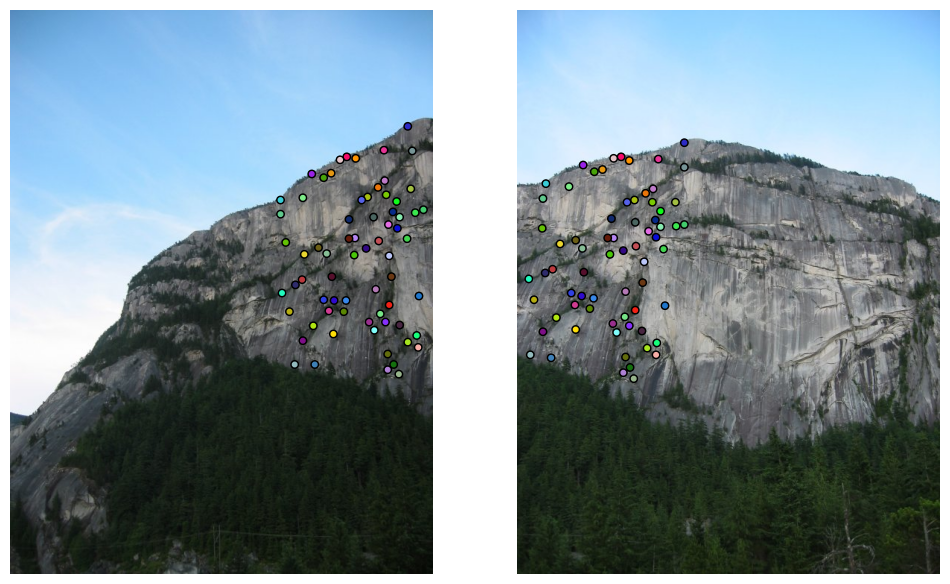

In [ ]:
"""
Perform RANSAC on interest point matches
"""
print('[ do ransac ]')
t0=time()
S, inliers = ransac.ransac_similarity(ip1,ipm)
t1=time()
num_inliers_s = np.sum(inliers)
print(' found '+str(num_inliers_s)+' matches')
print(' % .2f secs' % (t1-t0))

ip1c = ip1[:, inliers]
ipmc = ipm[:, inliers]

print('[ drawing matches ]')
t0=time()
axs=im_util.plot_many_images(im1,im2)
desc_ex.draw_matches_ax(ip1c, ipmc, axs[0], axs[1])
t1=time()
print(' % .2f secs' % (t1-t0))

# optionally plot descriptors for matched points
#inlier_id=np.flatnonzero(inliers)
#match_id=match_idx[inlier_id]
#interest_point.plot_matching_descriptors(desc1,desc2,inlier_id,match_id,plt)

### Complete the CamGeomerty class

**Rotation Estimation**

The next task is to estimate the true rotation between the images. To do this, we'll take a guess at the field of view of our input images, and use a closed form algorithm to estimate the rotation. Open the `CamGeomerty` class and complete the implementation of `compute_rotation`. You should find that a large number of the matches are consistent with your rotation, and the pairwise warped images should look sensible. Try experimenting with the field of view parameter. <font color='Tomato'>Q1: What is the best field of view for these images?</font>

<font color='MediumSeaGreen'>Ans: About 45 degrees. I tested values from 20 - 90 degrees, and the images lined up best between 40 and 45 degrees, where the matching error was smallest. At larger angles like 90 degrees, fewer matches fit and the alignment got worse.</font>

[ estimate rotation ]
 assuming fov=45
 num consistent with rotation = 69.0
 compute rotation succeeded!
  0.01 secs
[ test pairwise warp ]
  0.23 secs


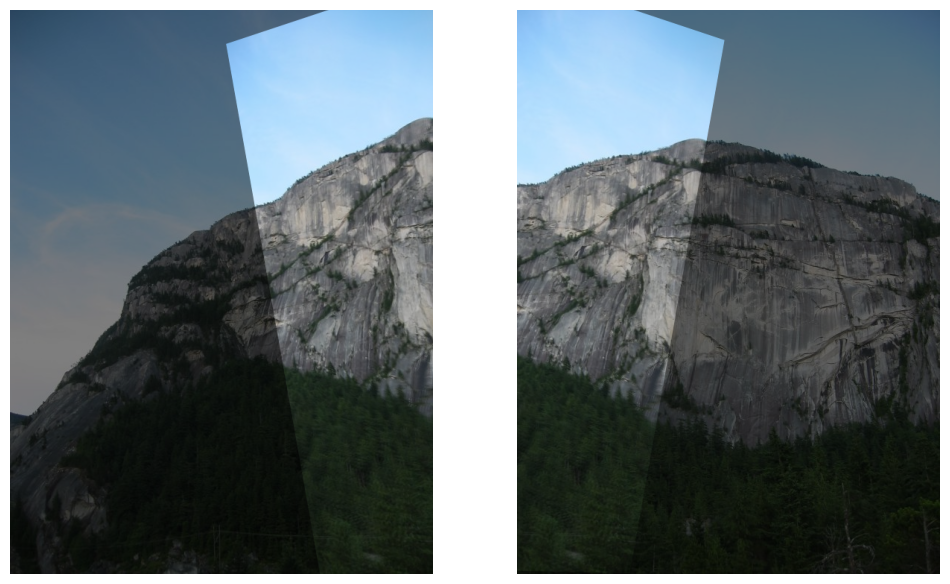

In [ ]:
"""
Estimate rotation matrix by least squares
"""
print('[ estimate rotation ]')
t0=time()
# Note: assume field of view of 45 degrees
fov_degrees=45
print(' assuming fov='+str(fov_degrees))
K1 = geometry.get_calibration(im1.shape, fov_degrees)
K2 = geometry.get_calibration(im2.shape, fov_degrees)
R,H = geometry.compute_rotation(ip1c, ipmc, K1, K2)

num_inliers_r = np.sum(ransac.consistent(H, ip1, ipm))
print(' num consistent with rotation = '+str(num_inliers_r))
if (num_inliers_r>0.9 * num_inliers_s):
    print(' compute rotation succeeded!')
t1=time()
print(' % .2f secs' % (t1-t0))

print('[ test pairwise warp ]')
t0=time()
im1_w, im2_w = render.pairwise_warp(im1, im2, H)
axs = im_util.plot_many_images(0.5*(im1+im2_w), 0.5*(im2+im1_w))
t1=time()
print(' % .2f secs' % (t1-t0))

The following code renders the aligned images in a spherical coordinate system. Check that the images are well aligned.

[ render aligned images ]
  0.38 secs


(np.float64(-0.5), np.float64(799.5), np.float64(532.5), np.float64(-0.5))

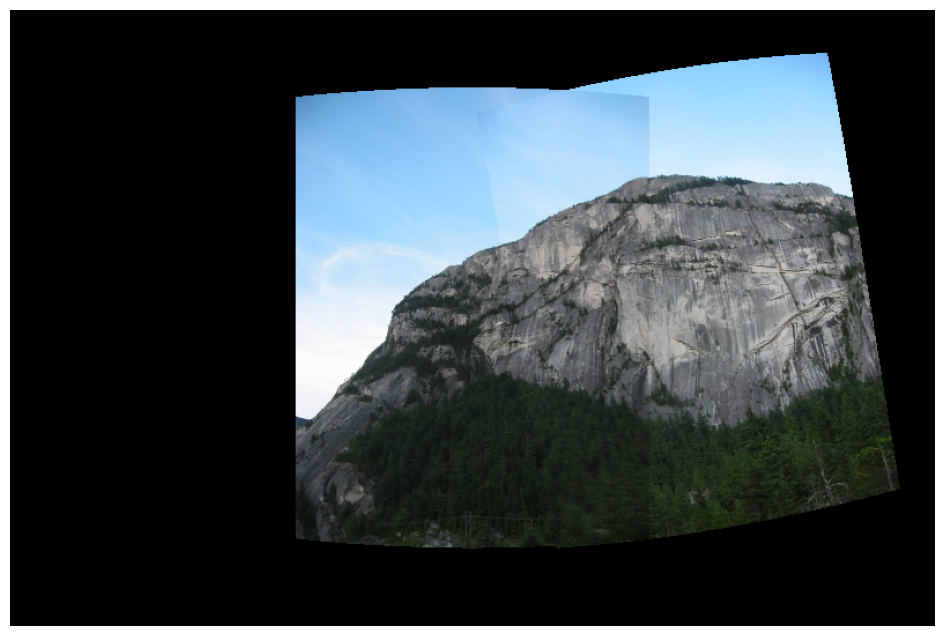

In [ ]:
"""
Render 2 images in spherical coordinates
"""
images=[im1,im2]
P1=K1
P2=np.dot(K2,R)
P_matrices=[P1,P2]

render_params={}
render_params['render_width']=800
render_params['theta_min']=-45
render_params['theta_max']=45
render_params['phi_min']=-30
render_params['phi_max']=30

print ('[ render aligned images ]')
t0=time()
pano_im=render.render_spherical(images, P_matrices, render_params)
t1=time()
print(' % .2f secs' % (t1-t0))

plt.plot()
plt.imshow(pano_im)
plt.axis('off')

Let's add more images! The `PanormaStitcher` class takes a set
of images as input and wraps the interest point and matching code in the method `match_images`. Take a look at this function and test it on a set of images using the code below.

In [ ]:

"""
Read a set of input images
"""

print('[ read images ]')
image_dir='data/'
im_filenames=os.listdir(image_dir)
im_filenames=[image_dir+fname for fname in im_filenames if not 'test' in fname]

images=[]
for fname in im_filenames:
  images.append(im_util.image_open(fname))

"""
Stitch images
"""
stitch_params={}
stitch_params['fov_degrees']=45

num_images = len(im_filenames)
print(' stitching '+str(num_images)+' images')

pano=PanoStitcher(images, stitch_params)
pano.match_images()

print(' num_matches=')
print(pano.num_matches)

[ read images ]
 stitching 7 images
[ find interest points ]
 found 421 interest points
 found 368 interest points
 found 556 interest points
 found 312 interest points
 found 582 interest points
 found 604 interest points
 found 614 interest points
  334.48 secs 
[ match descriptors ]
 image 0: num pts = 421
 image 1: num pts = 368
 image 2: num pts = 556
 image 3: num pts = 312
 image 4: num pts = 582
 image 5: num pts = 604
 image 6: num pts = 614
  69.11 secs
 num_matches=
[[  0.  91.  14.  77. 136.  72. 147.]
 [ 84.   0.  14.  15.   9. 193. 170.]
 [ 15.  10.   0.  86. 130.   7.   7.]
 [ 69.  15.  95.   0. 136.  12.  14.]
 [125.  18. 129. 138.   0.  11.  62.]
 [ 65. 201.  20.  13.  16.   0. 214.]
 [150. 178.  20.  16.  69. 205.   0.]]


### Test the CamGeometry class

To comfirm that your `compute_rotation` function is implemented correctly, run the unit test below.

In [ ]:
import unittest
# the collection of test cases
class TestCamGeometry(unittest.TestCase):

    def setUp(self):
        '''Set up an instance of Calculator pior to every test execution'''
        self.geometry = CamGeometry()

    def test_compute_rotation(self):
        '''Test case function for consistent'''
        print('\n[ Test of compute rotation ]')
        # calculated compute rotation results
        p1 = np.array([[1,2,3,4,5],[6,7,8,9,10]])
        p2 = np.array([[10,9,8,7,6],[5,4,3,2,1]])
        K1 = np.array([[1,2,3],[4,5,6],[0,0,1]])
        K2 = np.array([[9,8,7],[6,5,4],[0,0,1]])
        R_imp, H_imp = self.geometry.compute_rotation(p1,p2,K1,K2)

        # load expected results
        R_exp = np.load('data/test/cr_R.npy')
        H_exp = np.load('data/test/cr_H.npy')

        # error calculation
        print("\n With a simple numeric example:")
        print("\n The derived R matrix: ")
        print(R_imp)
        print("\n The expected R matrix: ")
        print(R_exp)
        print("\n The derived H matrix: ")
        print(H_imp)
        print("\n The expected H matrix: ")
        print(H_exp)
        self.assertTrue(np.allclose(R_imp, R_exp))
        self.assertTrue(np.allclose(H_imp, H_exp))

# to run the test
runner = unittest.TextTestRunner()
suite = unittest.TestLoader().loadTestsFromTestCase(TestCamGeometry)
runner.run(suite)

.
----------------------------------------------------------------------
Ran 1 test in 0.005s

OK



[ Test of compute rotation ]

 With a simple numeric example:

 The derived R matrix: 
[[ 0.18226387  0.17238984 -0.96801943]
 [ 0.95986018  0.18226387  0.21318609]
 [ 0.21318609 -0.96801943 -0.13225002]]

 The expected R matrix: 
[[ 0.18226387  0.17238984 -0.96801943]
 [ 0.95986018  0.18226387  0.21318609]
 [ 0.21318609 -0.96801943 -0.13225002]]

 The derived H matrix: 
[[-11.42368532   4.19599239   5.16226326]
 [ -6.84751857   2.54798677   2.64122317]
 [ -0.81607495   0.23044273   1.        ]]

 The expected H matrix: 
[[-11.42368532   4.19599239   5.16226326]
 [ -6.84751857   2.54798677   2.64122317]
 [ -0.81607495   0.23044273   1.        ]]


<unittest.runner.TextTestResult run=1 errors=0 failures=0>

### Complete the PanoStitcher class

**Panorama Alignment**:

In order to complete global panorama stitching, we need to compute a rotation matrix for each image (the first image is assumed to be the identity rotation) by chaining together pairwise relative rotations. This involves three steps:

1.   Figure out the stitch order of images based on the number of pairwise descriptor matches. (in `find_stitch_order`)
2.   Iteratively calculate rotation matrices for each image. (in `calculate_rotation_matrices`)
3. Reorder the images based on stitch order. (in `reorder_images`)

Complete implementation for the three above mentioned functions in the `PanoStitcher` class and review the `align_panorama` function to see how they come together.

Afterwards, you can use the `render` method to stitch all images in spherical coordinates, as shown in the code below.

final stitch_order:    [5, 6, 1, 0, 4, 2, 3]
[ render panorama ]
  1.00 secs


(np.float64(-0.5), np.float64(799.5), np.float64(544.5), np.float64(-0.5))

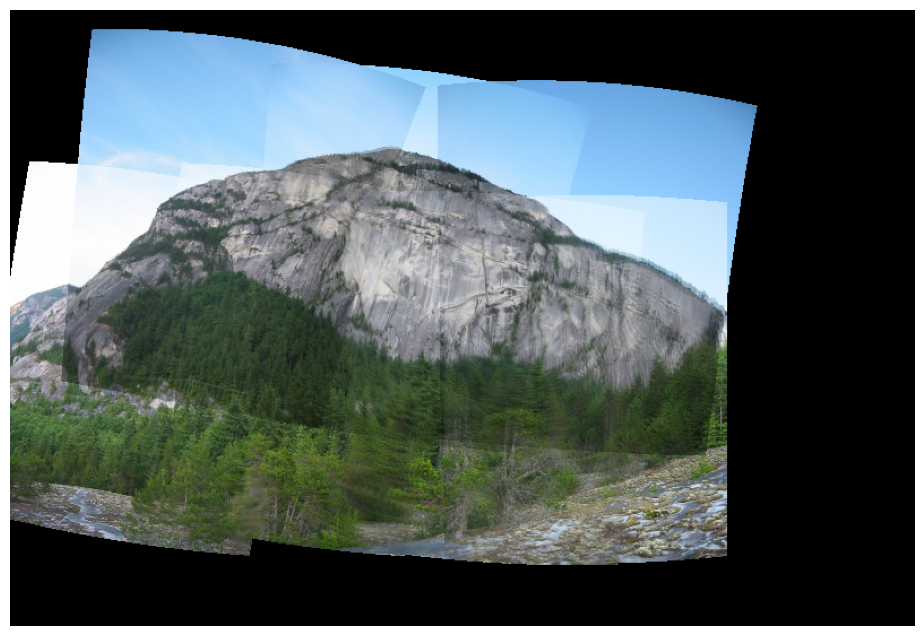

In [ ]:
pano.align_panorama()

render_params={}
render_params['render_width']=800
render_params['theta_min']=-70 #-45
render_params['theta_max']=40 # 45
render_params['phi_min']=-30
render_params['phi_max']=45#30

pano_im = pano.render(render_params)

plt.plot()
plt.imshow(pano_im)
plt.axis('off')

### Test the PanoStitcher class
Below is a unit testing class for the `PanoStitcher` class. Run the code cell below to verify the correstness of the code you implemented.

In [ ]:
import unittest
# the collection of test cases
class TestPanoStitcher(unittest.TestCase):

    def setUp(self):
        '''Set up an instance of Calculator pior to every test execution'''
        self.pano = PanoStitcher([])

    def test_find_stitch_order(self):
        '''Test case function for find_stitch_order'''
        print('\n[ Test find_stitch_order ]')
        # calculate stitch order
        # nm = np.random.randint(1, 1000, size=(10, 10))
        # np.fill_diagonal(nm,0)
        nm = np.load("data/test/fso_nm.npy")
        self.pano.set_num_matches(nm)
        self.pano.find_stitch_order()
        so_imp = self.pano.stitch_order

        # load expected stitch order results
        so_exp = np.load('data/test/fso_order.npy').tolist()
        print("expected stitch_order:", so_exp)
        print("\n")

        # error verification
        self.assertTrue(so_imp == so_exp)

    def test_reorder_images(self):
        '''Test case function for reorder_images'''
        print('\n[ Test reorder_images ]')
        original_images = [7,8,5,9,6]
        # calculate updated sequence
        self.pano.set_images(original_images)
        self.pano.stitch_order = [2,0,4,3,1]
        self.pano.reorder_images()
        updated_images = self.pano.images.copy()

        # load expected sequence
        expected_images = [5,7,6,9,8]

        # calculate error
        print("\nOriginal sequence: ",original_images)
        print("Shuffle order:     ",self.pano.stitch_order)
        print("Updated sequence:  ",updated_images)
        print("Expected outcome:  ",expected_images)
        self.assertTrue(updated_images == expected_images)

# to run the test
runner = unittest.TextTestRunner()
suite = unittest.TestLoader().loadTestsFromTestCase(TestPanoStitcher)
runner.run(suite)

..
----------------------------------------------------------------------
Ran 2 tests in 0.008s

OK



[ Test find_stitch_order ]

The num_matches matrix manually hard code to be:
[[  0 540 321 375 888 223   9   7  87 916]
 [202   0 723 628 182 517 620 821 528 776]
 [107 343   0 217 155 945   9 240 773 270]
 [128 308 548   0 290 719 505 686 834 319]
 [481 983 738  50   0  37 596 207 784 857]
 [411 600  31 308 521   0 743 477 623 593]
 [676 831 601 969  67 727   0 437 820 870]
 [ 96 736  23 660 798 366 837   0 364 276]
 [494 460 729 156 212 798 128 822   0 566]
 [578 915 901 219 114 660 801 152 398   0]]


final stitch_order:    [4, 1, 7, 6, 3, 8, 5, 9, 0, 2]
expected stitch_order: [4, 1, 7, 6, 3, 8, 5, 9, 0, 2]



[ Test reorder_images ]

Original sequence:  [7, 8, 5, 9, 6]
Shuffle order:      [2, 0, 4, 3, 1]
Updated sequence:   [5, 7, 6, 9, 8]
Expected outcome:   [5, 7, 6, 9, 8]


<unittest.runner.TextTestResult run=2 errors=0 failures=0>

## Improving my Panorama Stitcher [*extra credit]

You should now have a complete implementation of a basic panorama stitcher. Try it out using a few different image sets and make a note of any issues/artifacts in the results. How could the results be improved? Write a list of possible improvements, and think of new features you might like to add. Now implement some of these improvements / new features and document your work in the notebook below.

In [ ]:
### TODO your improvements to the panorama stitcher